## Project Title : Churn Prediction Project 

## Project Description: 
This project is known as churn prediction for a telecom company.  Imagine that we are working at a telecom company that offers phone and internet services, and we have a problem: some of our customers are churning. They no longer are using our services and are going to a different provider. We would like to prevent that from happening, so we develop a system for identifying these customers and offer them an incentive to stay. We want to target them with promotional messages and give them a discount. We also would like to understand why the model thinks our customers churn, and for that, we need to be able to interpret the model’s predictions.
 
We have collected a dataset where we’ve recorded some information about our customers: what type of services they used, how much they paid, and how long they stayed with us. We also know who canceled their contracts and stopped using our services (churned). We will use this information as the target variable in the machinelearning model and predict it using all other available information. 

The project plan is as follows: 
- First, we download the dataset and do some initial preparation: rename columns and change values inside columns to be consistent throughout the entire dataset.
- Then we split the data into train, validation, and test so we can validate our models.
- As part of the initial data analysis, we look at feature importance to identify which features are important in our data.
- We transform categorical variables into numeric variables so we can use them in the model.
- Finally, we train a logistic regression model.

## Dataset Description
- Url:  https://www.kaggle.com/blastchar/telco-customer-churn.

- Column description
    - CustomerID: the ID of the customer
    - Gender: male/female
    - SeniorCitizen: whether the customer is a senior citizen (0/1)
    - Partner: whether they live with a partner (yes/no)
    - Dependents: whether they have dependents (yes/no)
    - Tenure: number of months since the start of the contract
    - PhoneService: whether they have phone service (yes/no)
    - MultipleLines: whether they have multiple phone lines (yes/no/no phone service)
    - InternetService: the type of internet service (no/fiber/optic)
    - OnlineSecurity: if online security is enabled (yes/no/no internet)
    - OnlineBackup: if online backup service is enabled (yes/no/no internet)
    - DeviceProtection: if the device protection service is enabled (yes/no/no internet)
    - TechSupport: if the customer has tech support (yes/no/no internet)
    - StreamingTV: if the TV streaming service is enabled (yes/no/no internet)
    - StreamingMovies: if the movie streaming service is enabled (yes/no/no internet)
    - Contract: the type of contract (monthly/yearly/two years)
    - PaperlessBilling: if the billing is paperless (yes/no)
    - PaymentMethod: payment method (electronic check, mailed check, bank transfer, credit card)
    - MonthlyCharges: the amount charged monthly (numeric)
    - TotalCharges: the total amount charged (numeric)
    - Churn: if the client has canceled the contract (yes/no)



In [1]:
## librarie(s) for loading and preprocessing 
import numpy as np
import pandas as pd 

## libarie(s) for visualization 
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns

## library for building a validation framwork
from sklearn.model_selection import train_test_split

## library for feature engineering 
from sklearn.feature_extraction import DictVectorizer

## libraries for computing classification accuracy score
from sklearn.metrics import (f1_score, accuracy_score, recall_score, precision_score,confusion_matrix, roc_auc_score)

## library for ml algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier 
from sklearn.ensemble import (AdaBoostClassifier, GradientBoostingClassifier, RandomForestClassifier)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from sklearn.naive_bayes import GaussianNB

import warnings 
warnings.filterwarnings("ignore")

# Loading and Data Overview

In [2]:
# load dataset
data = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

# create a copy of the dataset
telco = data.copy()

In [4]:
# view first five rows
telco.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


In [7]:
# last five rows
telco.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [5]:
telco.shape

(7043, 21)

In [6]:
telco.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [7]:
# check for brief column summary
telco.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [9]:
telco.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [12]:
telco.TotalCharges.unique()

array(['29.85', '1889.5', '108.15', ..., '346.45', '306.6', '6844.5'],
      dtype=object)

# Data Processing
- Replacing empty stirngs with nan and filling for missing values
- change data type of TotalCharges and SeniorCitizen

In [13]:
## replace  values in totalcharges column 
#'coerce': Converts invalid parsing (non-numeric values) to NaN (Not a Number),
#allowing for a more robust handling of mixed data types.
telco.TotalCharges = pd.to_numeric(telco.TotalCharges, errors='coerce') 

In [16]:
telco.TotalCharges.dtype

dtype('float64')

In [17]:
telco.TotalCharges = telco.TotalCharges.astype('float64')
telco.SeniorCitizen = telco.SeniorCitizen.astype('object')

In [21]:
telco.TotalCharges.mean()

2283.3004408418656

In [22]:
telco.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   object 
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


Descriptives and exploration

In [25]:
telco.describe().round(2)

,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7032.00
mean,32.37,64.76,2283.30
std,24.56,30.09,2266.77
min,0.00,18.25,18.80
25%,9.00,35.50,401.45
50%,29.00,70.35,1397.48
75%,55.00,89.85,3794.74
max,72.00,118.75,8684.80


In [30]:
telco.PaymentMethod.mode()[0]

'Electronic check'

In [32]:
telco.PaymentMethod.value_counts(ascending= True)

PaymentMethod
Credit card (automatic)      1522
Bank transfer (automatic)    1544
Mailed check                 1612
Electronic check             2365
Name: count, dtype: int64

In [12]:
# replace nan with median because of skewness in TotalCharges
telco.TotalCharges.fillna(telco.TotalCharges.median(), inplace=True)

In [33]:
# convert the target column into yes == 1 and n == 0
telco.Churn = (telco.Churn == 'Yes').astype(int)

In [14]:
telco.Churn.head()

0    0
1    0
2    1
3    0
4    1
Name: Churn, dtype: int32

# Data Exploration

In [15]:
# What percentage of customers have churned?
telco.Churn.value_counts(normalize = True).round(4) * 100

Churn
0    73.46
1    26.54
Name: proportion, dtype: float64

26.54% of customers have churned

Text(0.5, 1.0, 'Correlation Matrix')

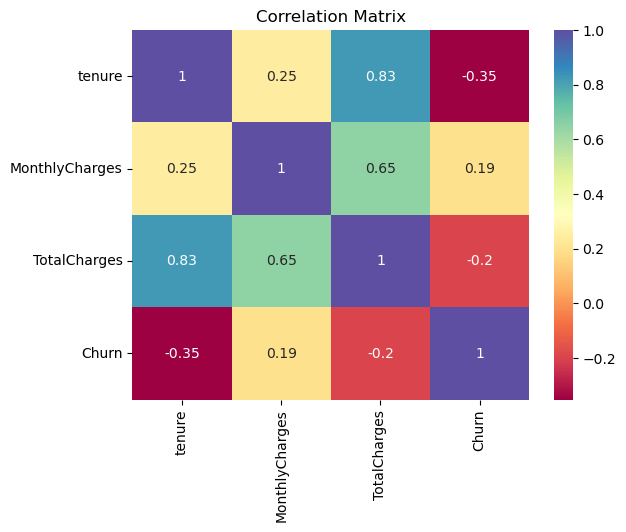

In [16]:
# correlation between numeric variables
telco_num = telco.select_dtypes(exclude = 'O')
sns.heatmap(telco_num.corr(), annot=True, cmap='Spectral')
plt.title('Correlation Matrix')

- A strong positive correlation between tenure and total charges signfying high accumulated bills for long term customers.
- Another strong positive correlation between monthly charges and total charges. We can infer that mostly higher monthly charges leads to higher total charges which makes sense practically
- A weak positive correlation exist for the tenure and monthly charges


In [35]:
telco.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [39]:
telco.groupby("Churn")['TotalCharges'].mean().round(2)

Churn
0    2555.34
1    1531.80
Name: TotalCharges, dtype: float64

In [41]:
telco.groupby("Churn")['MonthlyCharges'].mean().round(2)

Churn
0    61.27
1    74.44
Name: MonthlyCharges, dtype: float64

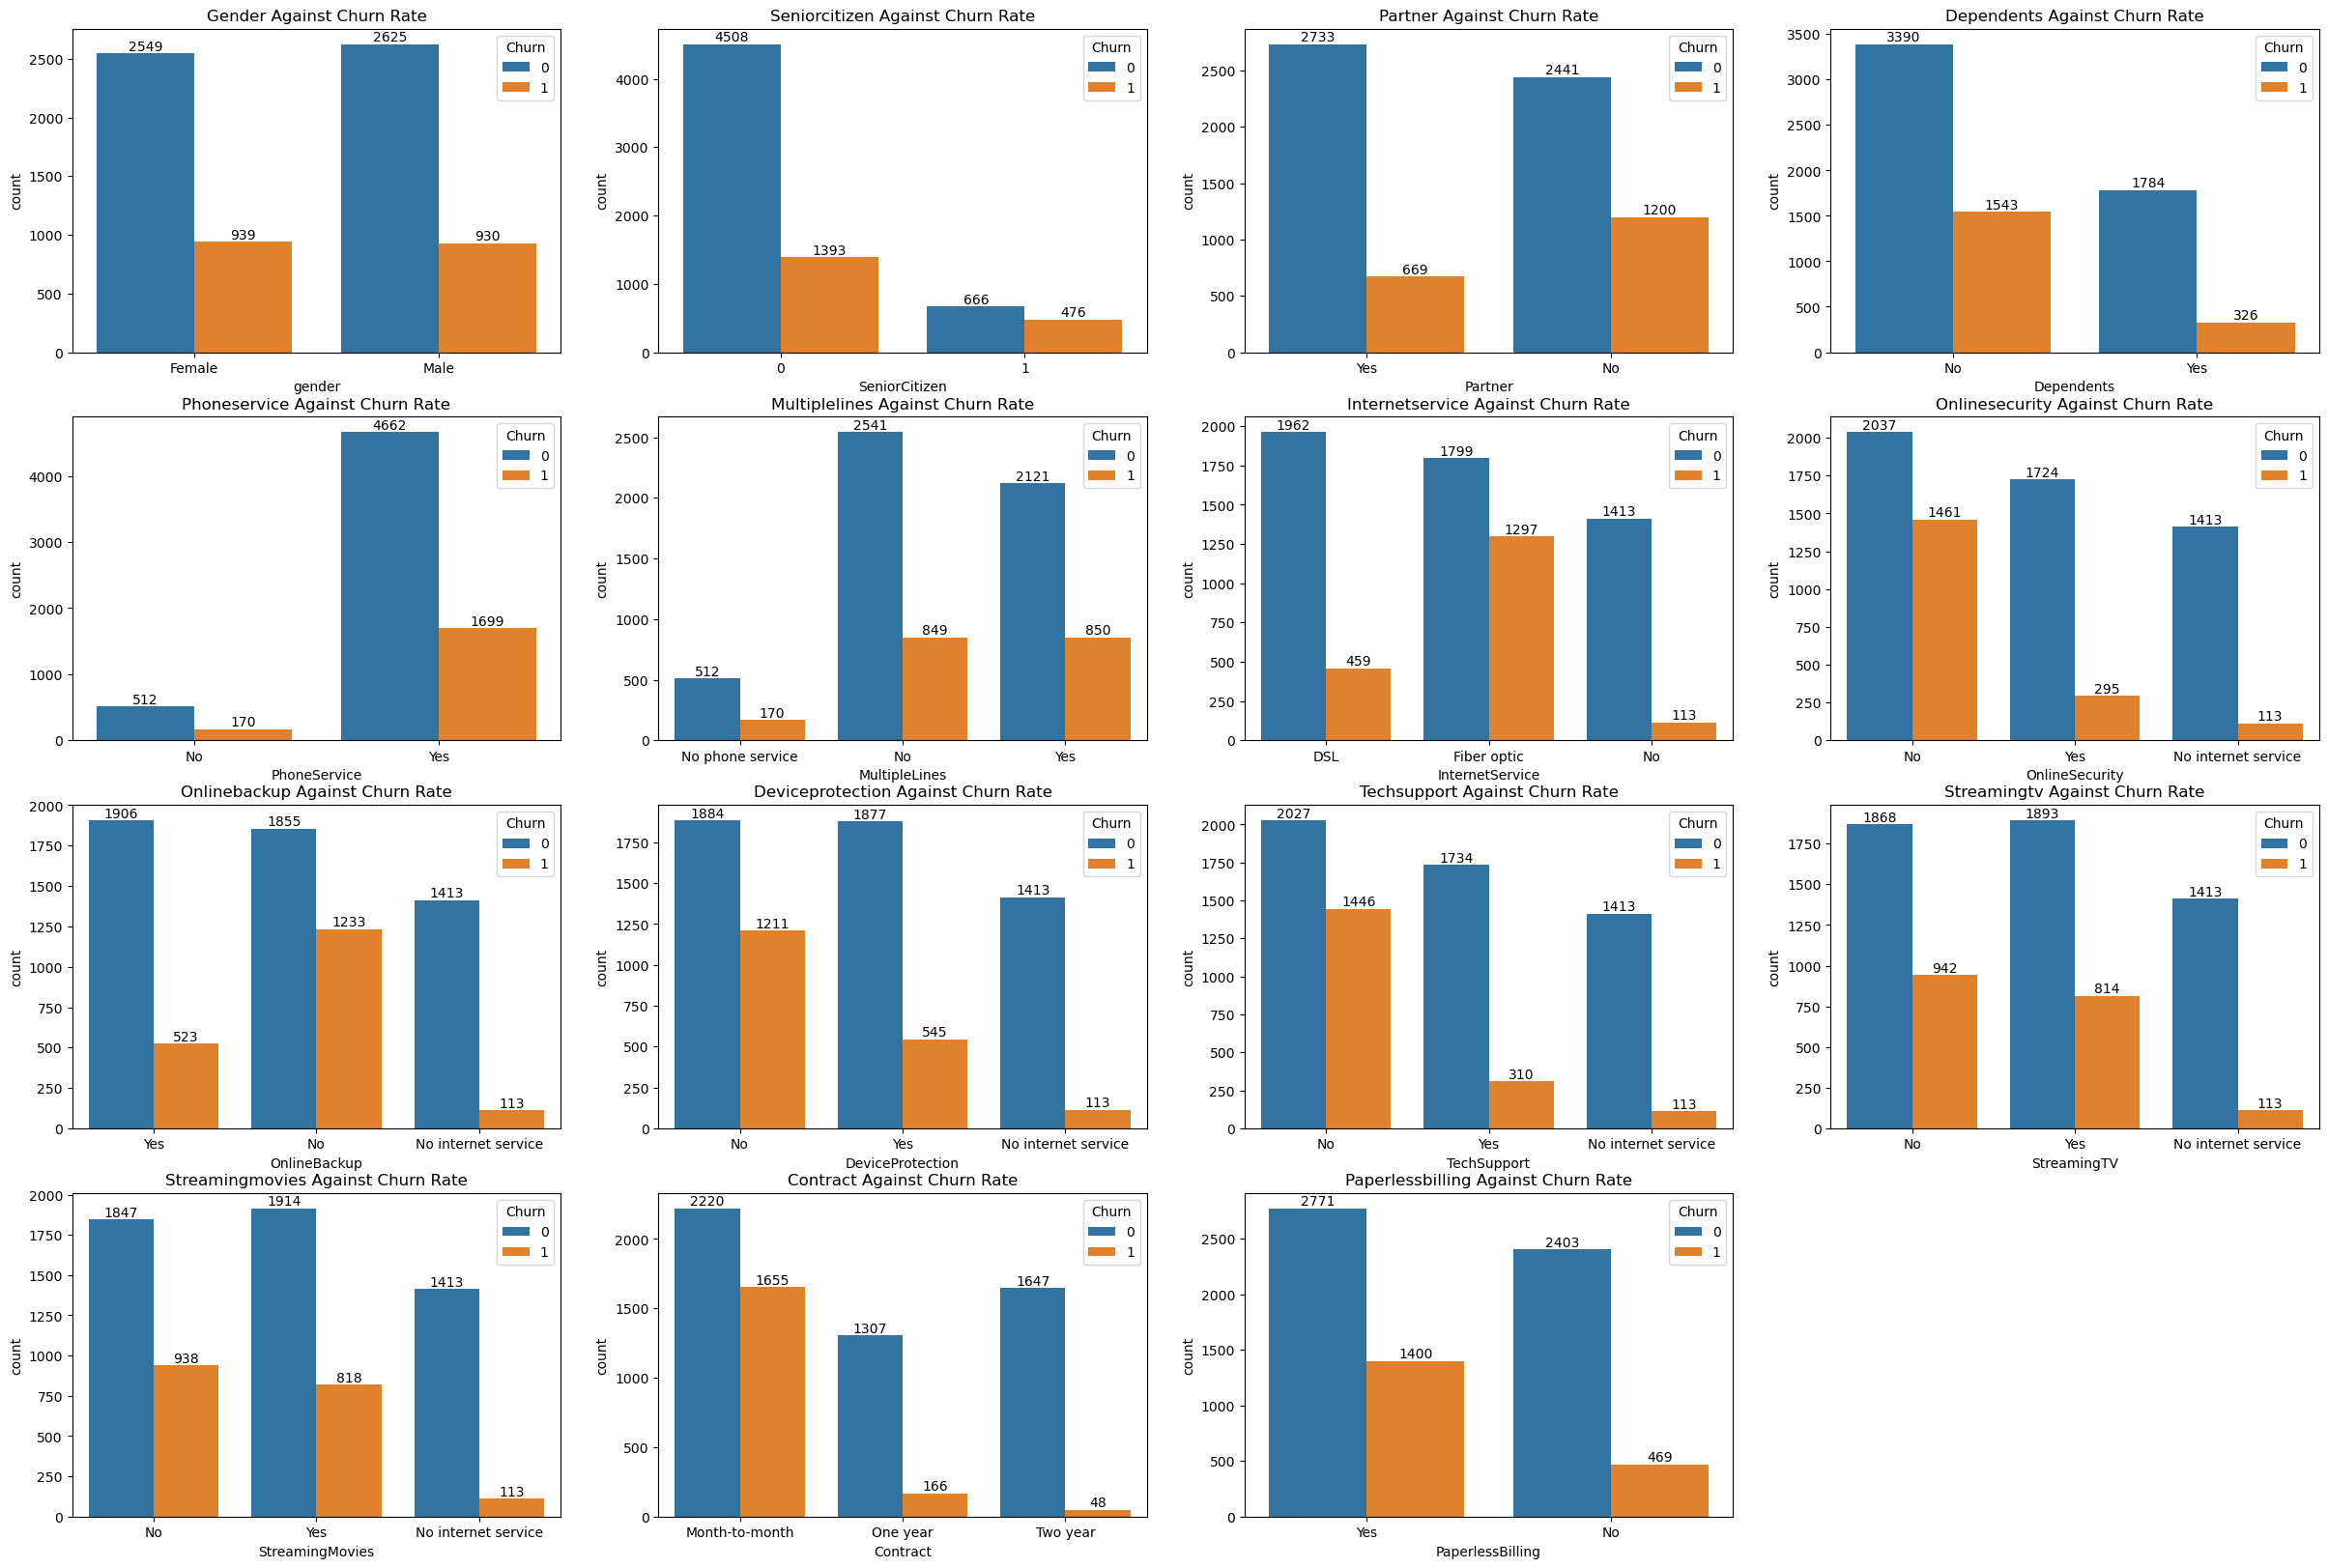

In [17]:
# graphical representation of the immediate above
categorical_cols = list(telco.select_dtypes(include=['object']).columns)
fig = plt.figure(figsize = (30,20))
i = 0
for column in categorical_cols[1:-1]:
    i += 1
    plt.subplot(4, 4, i)
    ax = sns.countplot(telco, x = column, hue = 'Churn')
    plt.title(f'{column.title()} Against Churn Rate')
    for container in ax.containers: # for loop to display the the count
        ax.bar_label(container)

plt.show()

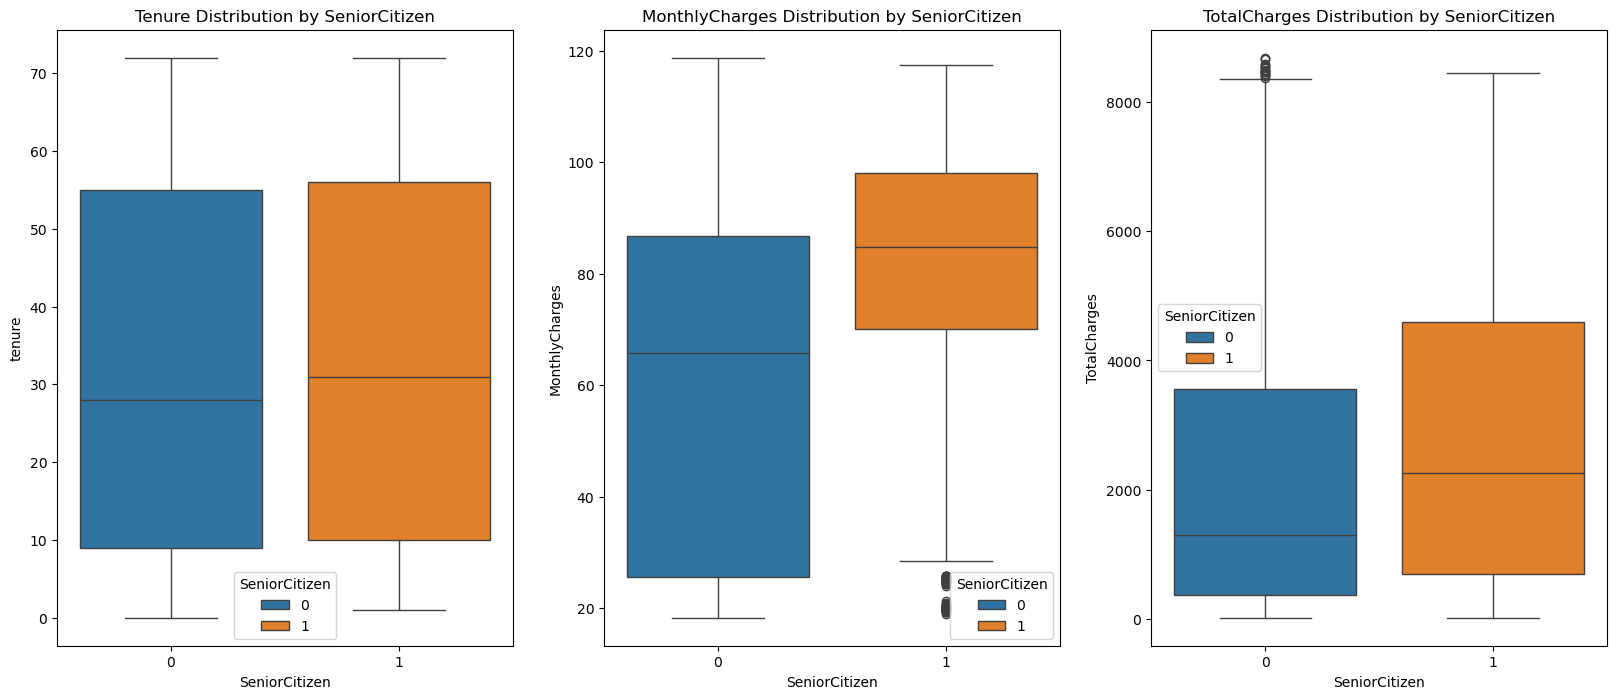

In [18]:
# Boxplot for SeniorCitizen vs Tenure
fig = plt.figure(figsize = (20, 8))
plt.subplot(1,3,1)
sns.boxplot(x='SeniorCitizen', y='tenure', data=telco, hue='SeniorCitizen')
plt.title('Tenure Distribution by SeniorCitizen')


# Boxplot for SeniorCitizen vs MonthlyCharges
plt.subplot(1,3,2)
sns.boxplot(x='SeniorCitizen', y='MonthlyCharges', data=telco, hue = 'SeniorCitizen')
plt.title('MonthlyCharges Distribution by SeniorCitizen')


# Boxplot for SeniorCitizen vs TotalCharges
plt.subplot(1,3,3)
sns.boxplot(x='SeniorCitizen', y='TotalCharges', data=telco, hue = 'SeniorCitizen')
plt.title('TotalCharges Distribution by SeniorCitizen')
plt.show()

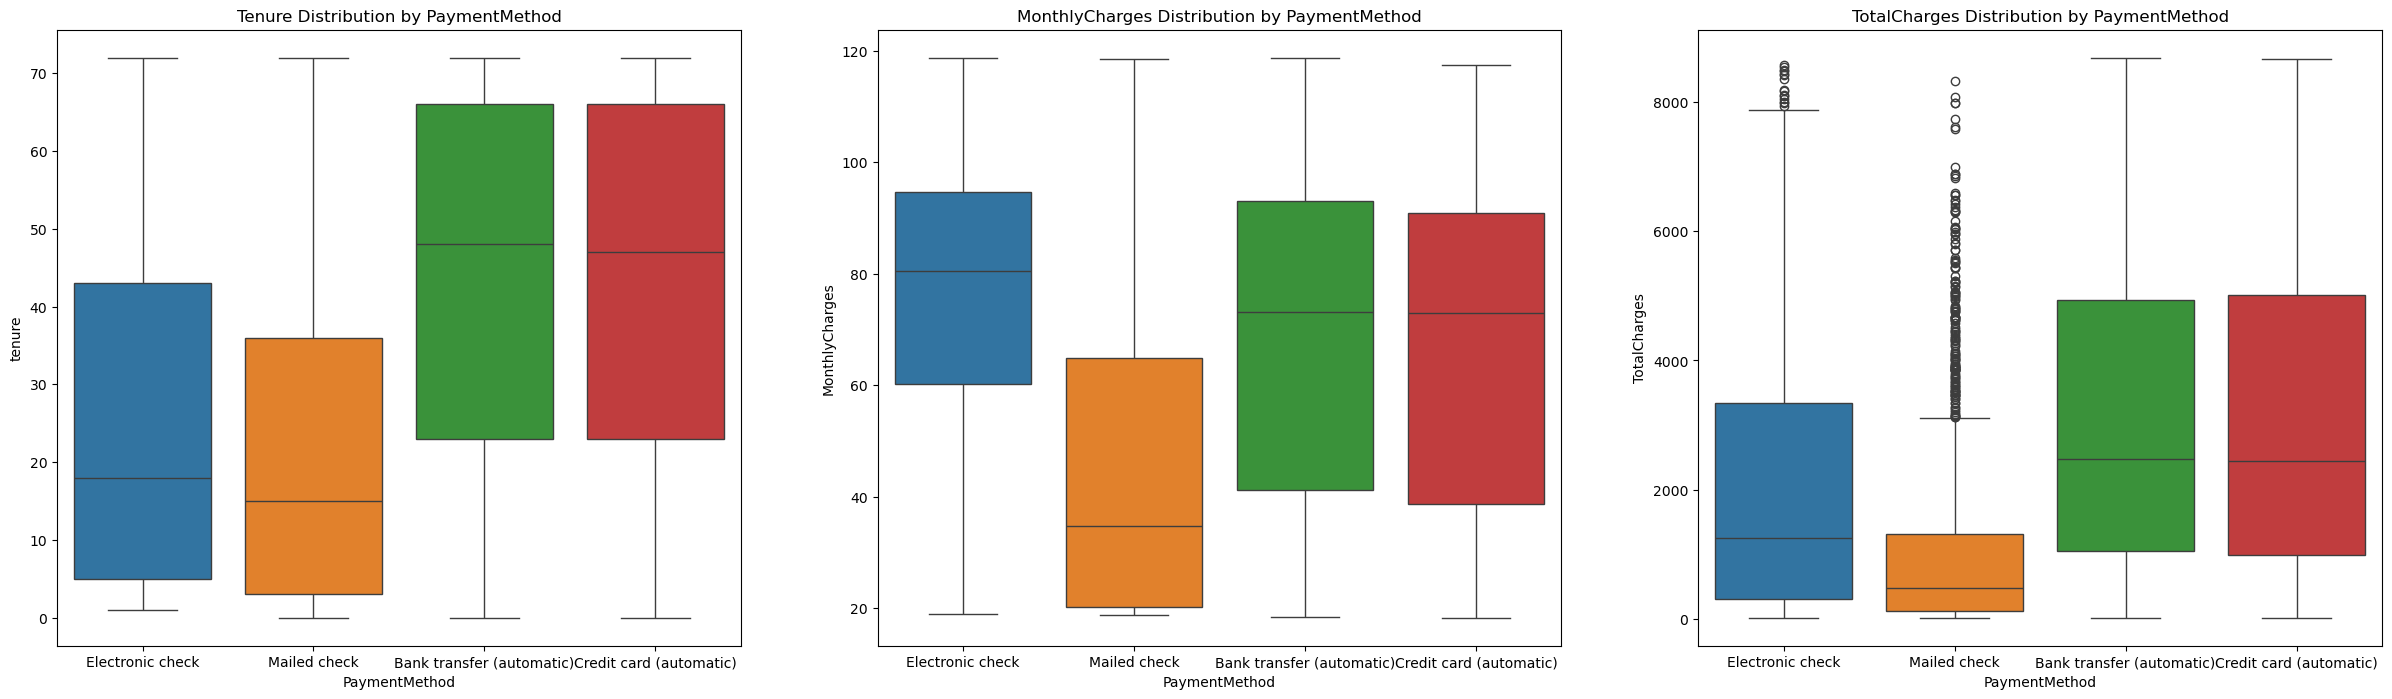

In [19]:
# Boxplot for PaymentMethod vs Tenure
fig = plt.figure(figsize = (30, 8))
plt.subplot(1,3,1)
sns.boxplot(x='PaymentMethod', y='tenure', data=telco, hue='PaymentMethod')
plt.title('Tenure Distribution by PaymentMethod')


# Boxplot for PaymentMethod vs MonthlyCharges
plt.subplot(1,3,2)
sns.boxplot(x='PaymentMethod', y='MonthlyCharges', data=telco, hue = 'PaymentMethod')
plt.title('MonthlyCharges Distribution by PaymentMethod')


# Boxplot for PaymentMethod vs TotalCharges
plt.subplot(1,3,3)
sns.boxplot(x='PaymentMethod', y='TotalCharges', data=telco, hue = 'PaymentMethod')
plt.title('TotalCharges Distribution by PaymentMethod')
plt.show()

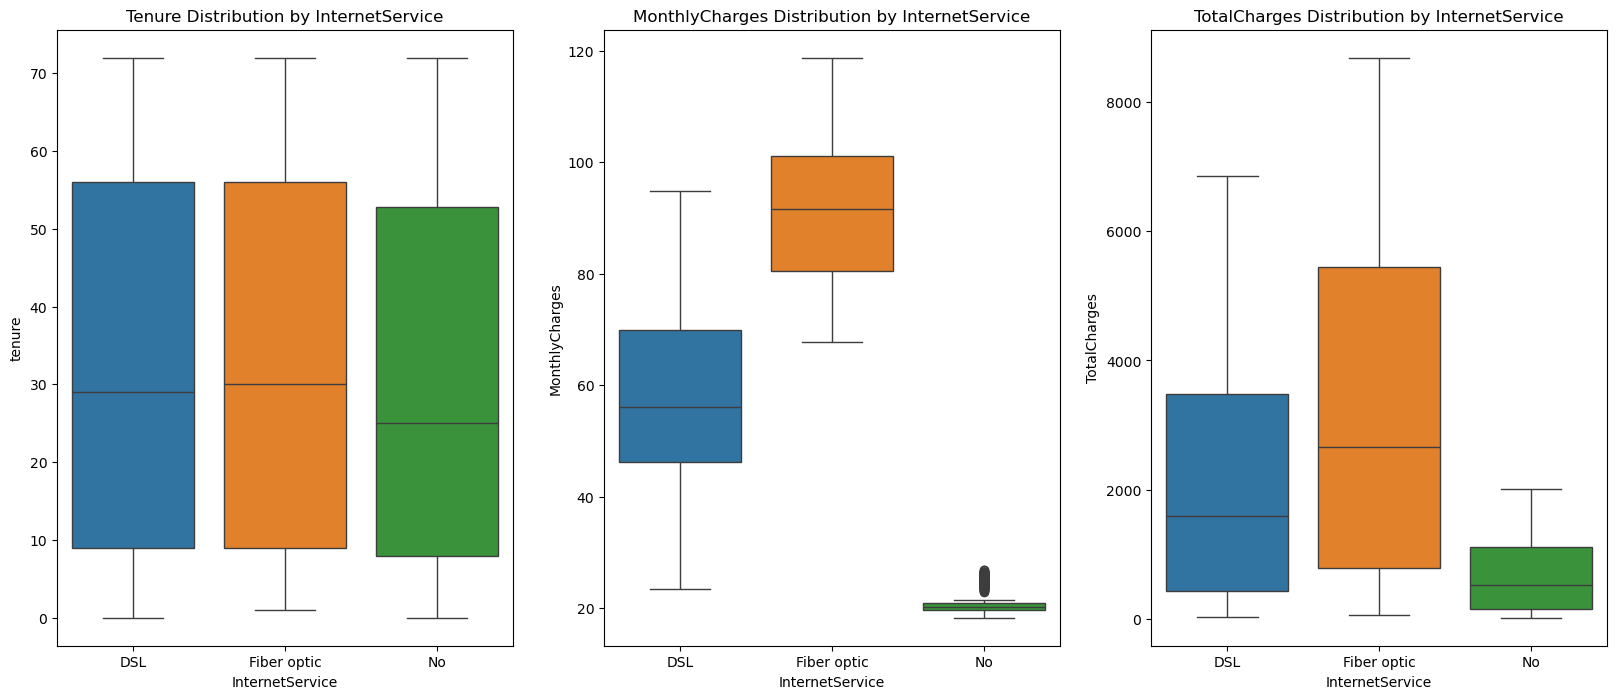

In [20]:
# Boxplot for InternetService vs Tenure
fig = plt.figure(figsize = (20, 8))
plt.subplot(1,3,1)
sns.boxplot(x='InternetService', y='tenure', data=telco, hue='InternetService')
plt.title('Tenure Distribution by InternetService')


# Boxplot for InternetService vs MonthlyCharges
plt.subplot(1,3,2)
sns.boxplot(x='InternetService', y='MonthlyCharges', data=telco, hue = 'InternetService')
plt.title('MonthlyCharges Distribution by InternetService')


# Boxplot for InternetService vs TotalCharges
plt.subplot(1,3,3)
sns.boxplot(x='InternetService', y='TotalCharges', data=telco, hue = 'InternetService')
plt.title('TotalCharges Distribution by InternetService')
plt.show()

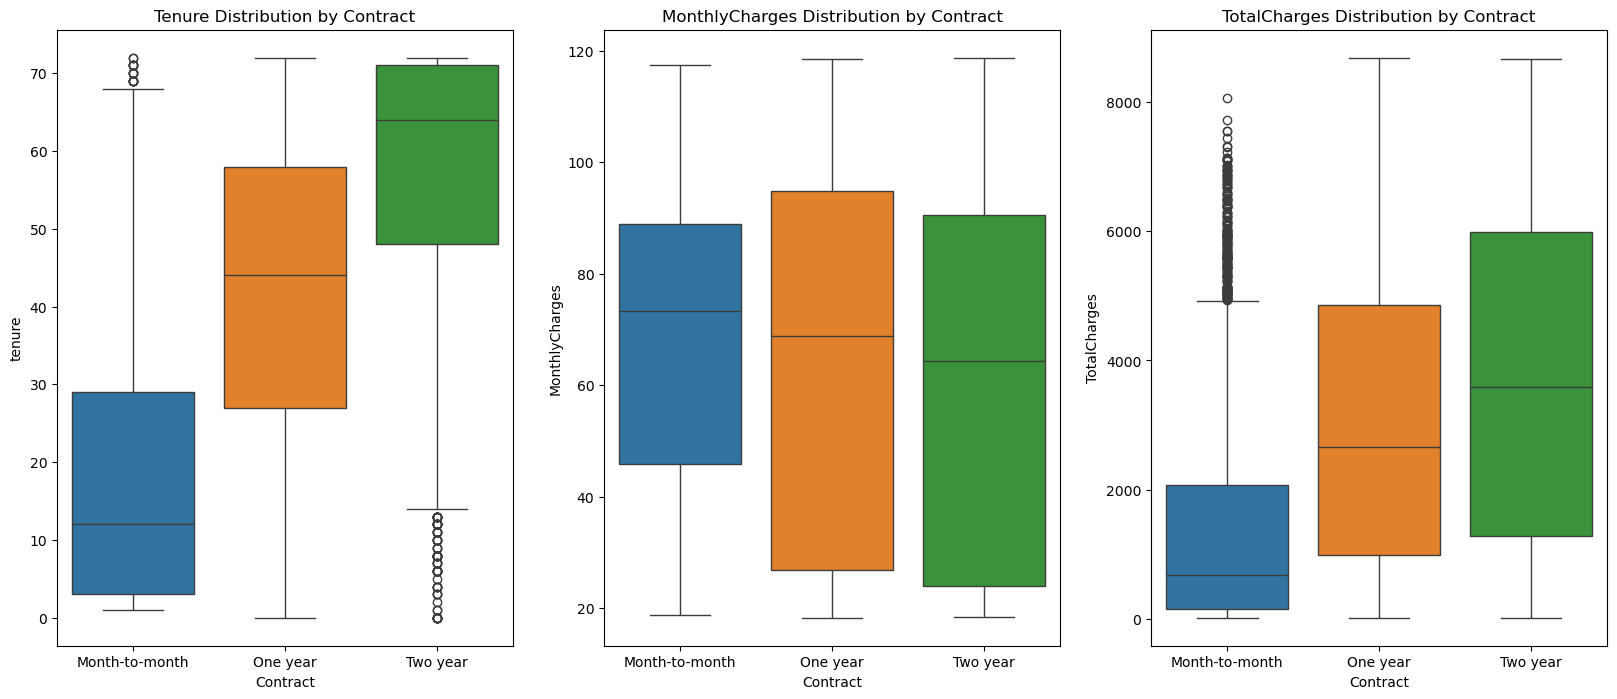

In [21]:
# Boxplot for Contract vs Tenure
fig = plt.figure(figsize = (20, 8))
plt.subplot(1,3,1)
sns.boxplot(x='Contract', y='tenure', data=telco, hue='Contract')
plt.title('Tenure Distribution by Contract')


# Boxplot for Contract vs MonthlyCharges
plt.subplot(1,3,2)
sns.boxplot(x='Contract', y='MonthlyCharges', data=telco, hue = 'Contract')
plt.title('MonthlyCharges Distribution by Contract')


# Boxplot for Contract vs TotalCharges
plt.subplot(1,3,3)
sns.boxplot(x='Contract', y='TotalCharges', data=telco, hue = 'Contract')
plt.title('TotalCharges Distribution by Contract')
plt.show()

<Axes: xlabel='Churn', ylabel='MonthlyCharges'>

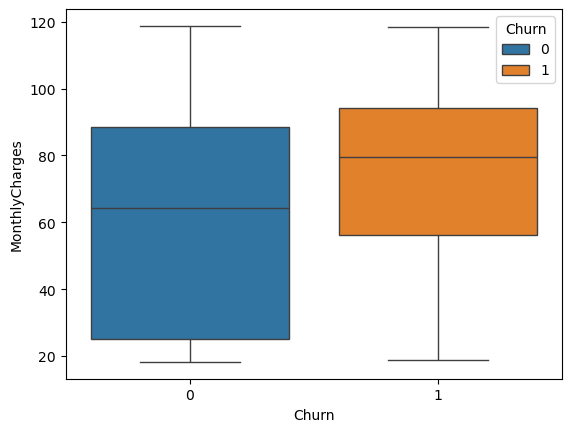

In [22]:
sns.boxplot(telco, x = 'Churn', y= 'MonthlyCharges', hue='Churn')

- Customers who are leaving are paying higher monthly charges on average

In [23]:
del telco['customerID']

In [24]:
telco.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


# Splitting the dataset
- Training 80%
- Validation 10%
- Testing 10%

In [25]:
df_train_full, df_test = train_test_split(telco, test_size = 0.1, random_state = 18)
df_train, df_valid = train_test_split(df_train_full, test_size = 1/9, random_state = 18)

print(f'Training dataset {df_train.shape}')
print(f'Validation dataset {df_valid.shape}')
print(f'Testing dataset {df_test.shape}')

Training dataset (5633, 20)
Validation dataset (705, 20)
Testing dataset (705, 20)


In [25]:
df_train_full, df_test = train_test_split(telco, test_size = 0.1, random_state = 18)
df_train, df_valid = train_test_split(df_train_full, test_size = 1/9, random_state = 18)

print(f'Training dataset {df_train.shape}')
print(f'Validation dataset {sdf_valid.shape}')
print(f'Testing dataset {df_test.shape}')

Training dataset (5633, 20)
Validation dataset (705, 20)
Testing dataset (705, 20)


In [26]:
# select target column
y_train = df_train['Churn'].values
y_valid = df_valid['Churn'].values
y_test = df_test['Churn'].values

In [27]:
# delete target columns from the rest of the dataframe
del df_train['Churn']
del df_valid['Churn']
del df_test['Churn']

In [28]:
# confirm deleted churn variable
df_train.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
573,Male,0,Yes,No,56,Yes,Yes,Fiber optic,No,Yes,No,No,Yes,Yes,One year,No,Credit card (automatic),100.30,5614.45
821,Male,0,Yes,Yes,43,Yes,No,DSL,Yes,No,Yes,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),79.15,3566.60
4952,Male,0,No,No,2,Yes,No,Fiber optic,Yes,Yes,No,No,Yes,Yes,Month-to-month,No,Electronic check,100.20,198.50
7019,Female,0,No,No,39,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.15,826.00
6571,Female,0,No,No,34,Yes,No,DSL,Yes,Yes,No,No,No,No,One year,No,Mailed check,55.00,1885.15


# Feature Engineering

In [29]:
# convert dataframe into dict
train_dict = df_train.to_dict(orient = 'records')
train_valid = df_valid.to_dict(orient = 'records')

# train the vectorizer with train_dict (encoding)
dv = DictVectorizer()
dv.fit(train_dict)

# transform data into arrays
X_train = dv.transform(train_dict).toarray()
X_valid = dv.transform(train_valid).toarray()

print('Training Data Shape:',X_train.shape)
print('Validation Data Shape:',X_valid.shape)

Training Data Shape: (5633, 45)
Validation Data Shape: (705, 45)


# Training Models

In [30]:
LR_model = LogisticRegression(solver = 'liblinear')
DTC_model = DecisionTreeClassifier(random_state=0, criterion='entropy')
RFC_model = RandomForestClassifier(n_estimators=120, random_state=0, criterion='entropy', n_jobs=-1)
GBC_model = GradientBoostingClassifier(n_estimators= 120,random_state=0, learning_rate= 0.9)
ABC_model = AdaBoostClassifier(n_estimators= 120,random_state=0, learning_rate= 0.9)
SVC_model = SVC()
KNC_model = KNeighborsClassifier()
XGBC_model = XGBClassifier()
GNB_model = GaussianNB()

In [48]:
#storing all the models in a list
models=[LR_model, DTC_model,RFC_model,GBC_model,ABC_model,SVC_model,KNC_model,XGBC_model,GNB_model]
summary = {} # a dictionary to collect and store evaluation summary

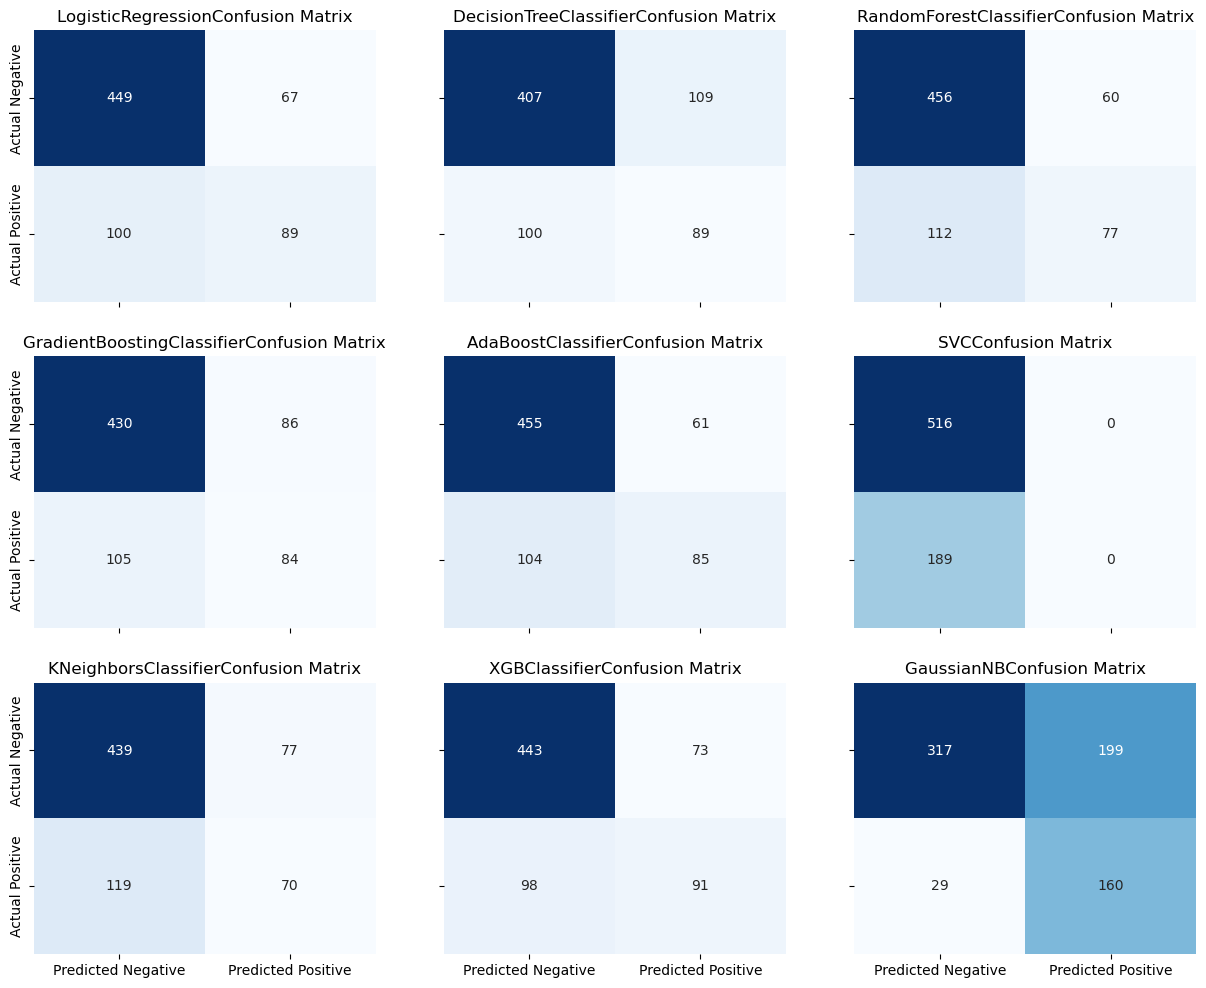

In [50]:
fig, axis = plt.subplots(3,3,sharex=True, sharey=True,figsize=(15,12)) # defining a ploting space for the confusion matrix
for i,model in enumerate(models): # calling the model and index
    model.fit(X_train, y_train)
    prediction =model.predict(X_valid)
    Accuracy = accuracy_score(y_valid, prediction) #Accuracy
    Precision = precision_score(y_valid, prediction) 
    Recall =recall_score(y_valid, prediction) 
    F1_Score =f1_score(y_valid, prediction) 
    AUC_Score =roc_auc_score(y_valid, prediction) 
    summary[str(model).split("(")[0]]= [round(Accuracy,5),float(round(Precision,5)), float(round(Recall,5)), float(round(F1_Score,5)),float(round(AUC_Score,5))] # Storing all the metrics info in a dictionary

    axis = axis.flatten()
    
    sns.heatmap(confusion_matrix(y_valid, prediction),annot=True,fmt='d',cmap='Blues', xticklabels=['Predicted Negative', 'Predicted Positive'], yticklabels=['Actual Negative', 'Actual Positive'],ax = axis[i],cbar=False).set(title=str(model).split("(")[0] + "Confusion Matrix")
    # a plot of the confusion matrix of each model

In [47]:
summary_table = pd.DataFrame.from_dict(summary,orient='index',columns=['Accuracy', 'Precision','Recal','F1_Score','AUC_Score']) # converting the dictionary to dataframe
summary_table.index = summary_table.index.rename('Model') #renaming the index to model name
summary_table.reset_index()

,Model,Accuracy,Precision,Recal,F1_Score,AUC_Score
0,LogisticRegression,0.76312,0.57051,0.47090,0.51594,0.67053
1,DecisionTreeClassifier,0.70355,0.44949,0.47090,0.45995,0.62983
2,RandomForestClassifier,0.75603,0.56204,0.40741,0.47239,0.64556


 Saving the best performing model

In [34]:
# import pickle library
import pickle

# specify where to save the file
with open('churn-model.bin', 'wb') as f_out:
    # save the model
    pickle.dump((dv, ABC_model), f_out)

# Loading Model

In [35]:
with open('churn-model.bin', 'rb') as f_in:
    dv, model = pickle.load(f_in)

In [36]:
## a sample customer
customer = {
 'customerid': '8879-zkjof',
 'gender': 'female',
 'SeniorCitizen': 0,
 'Partner': 'no',
 'Dependents': 'no',
 'tenure': 41,
 'PhoneService': 'yes',
 'MultipleLines': 'no',
 'InternetService': 'dsl',
 'OnlineSecurity': 'yes',
 'OnlineBackup': 'no',
 'DeviceProtection': 'yes',
 'TechSupport': 'yes',
 'StreamingTV': 'yes',
 'StreamingMovies': 'yes',
 'Contract': 'one_year',
 'PaperlessBilling': 'yes',
 'PaymentMethod': 'bank_transfer_(automatic)',
 'MonthlyCharges': 79.85,
 'TotalCharges': 3320.75,
}

In [37]:
# create a function to make a single prediction
def predict_single(customer, dv, model):
    X = dv.transform([customer])
    y_predict = model.predict(X)[0]
    return y_predict

In [38]:
# call the function to make the prediction
prediction = predict_single(customer, dv, model)
print(f'{prediction}')

0


In [39]:
# lets make the prediction by setting the threshold and returning a verdict
# 'verdict: Churn' , 'verdict: Not Churn'
if prediction == 1:
    print('Verdict: Churn')
else: print('Verdict: Not Churn')

Verdict: Not Churn
